## EXPLANATION DATASET

Heart Disease Classification Problem

This dataset presents a binary classification problem focused on predicting the presence or absence of heart disease in patients based on various medical and demographic features.
Dataset Overview:

1) 918 patient records
2) Target variable: “HeartDisease” (1 = present, 0 = absent)
3) Features include age, sex, chest pain type, resting blood pressure, cholesterol, fasting blood sugar, ECG results, and more

## LOAD DATA

We load the data and then we visualized

In [ ]:
import pandas as pd
import numpy as np

data = pd.read_csv('../data/heart.csv')

In [ ]:
data.info()
data.describe(include='all')
display(data.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    object 
 2   ChestPainType   918 non-null    object 
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    object 
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    object 
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    object 
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), object(5)
memory usage: 86.2+ KB


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


## DATA CLEANING
1) Check for missing values 
2) Outliers


In [ ]:
# Ckeck for missing values
missing_values = data.isnull().sum()
na_values = data.isna().sum

print("Valores faltantes en cada columna:")
print(missing_values)

print("Valores nan en cada columna:")
print(na_values)

Valores faltantes en cada columna:
Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64
Valores nan en cada columna:
<bound method DataFrame.sum of        Age    Sex  ChestPainType  RestingBP  Cholesterol  FastingBS  \
0    False  False          False      False        False      False   
1    False  False          False      False        False      False   
2    False  False          False      False        False      False   
3    False  False          False      False        False      False   
4    False  False          False      False        False      False   
..     ...    ...            ...        ...          ...        ...   
913  False  False          False      False        False      False   
914  False  False          False      False        False      False   
915  False  F

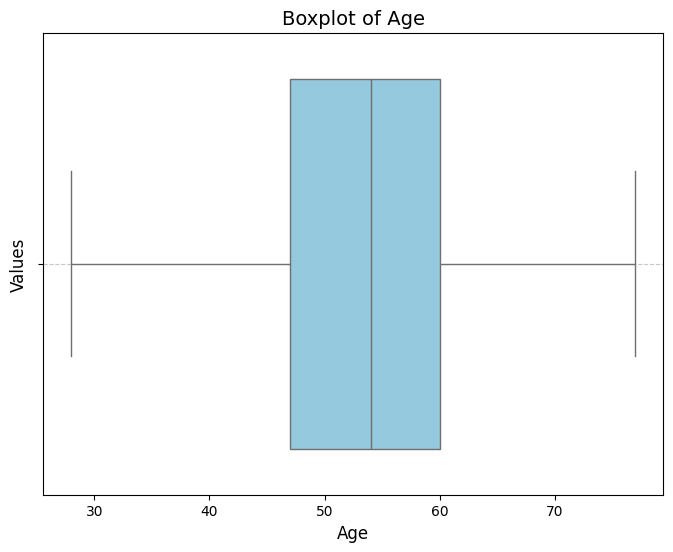

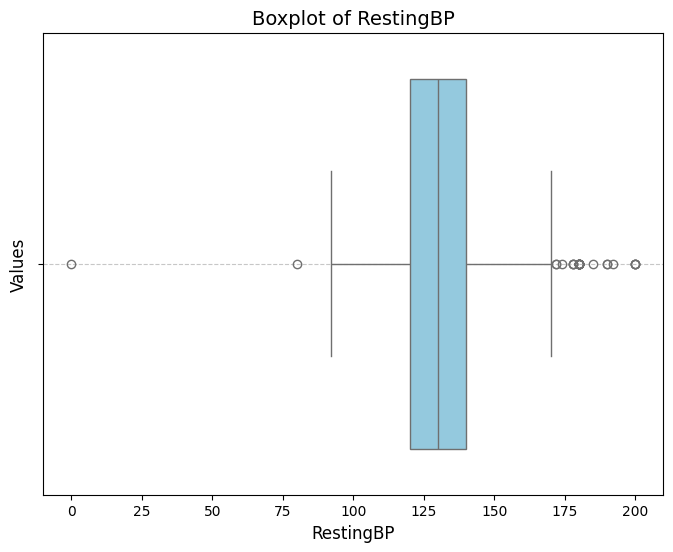

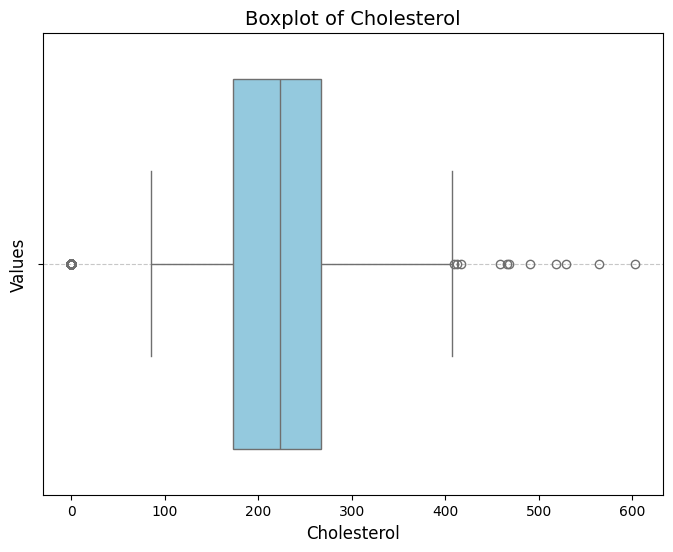

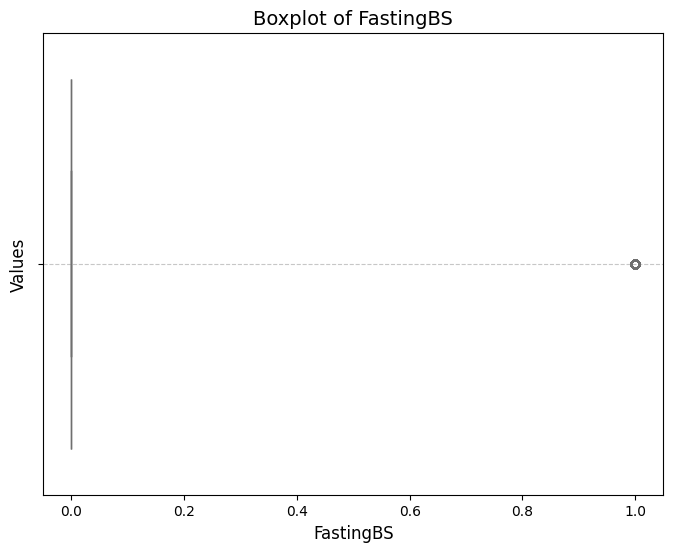

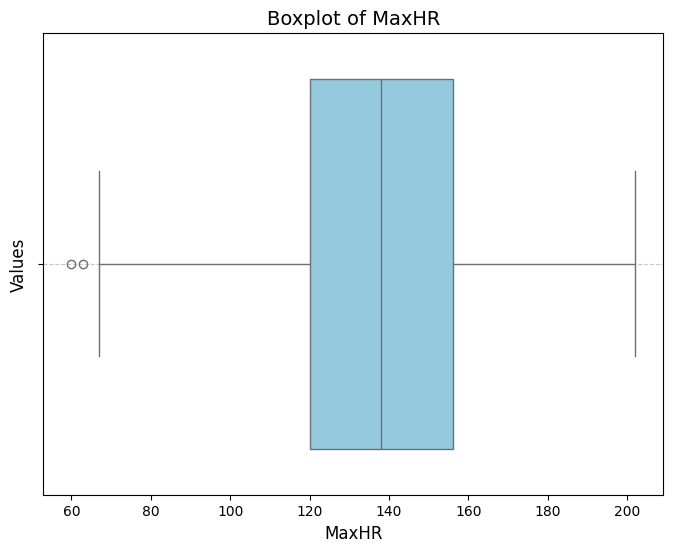

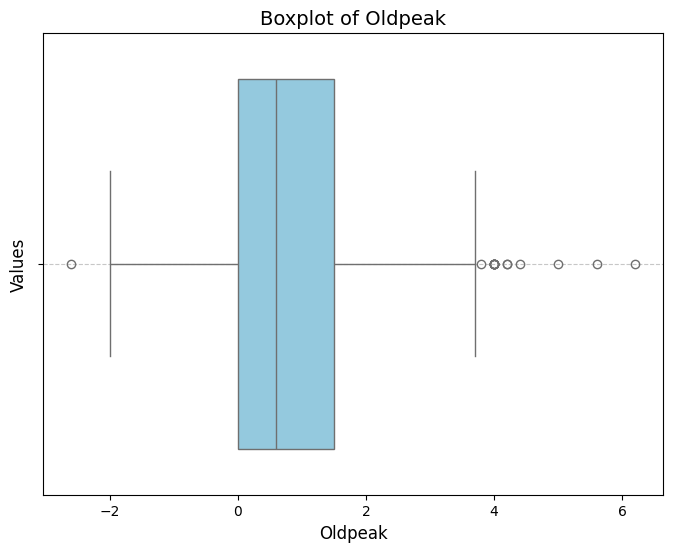

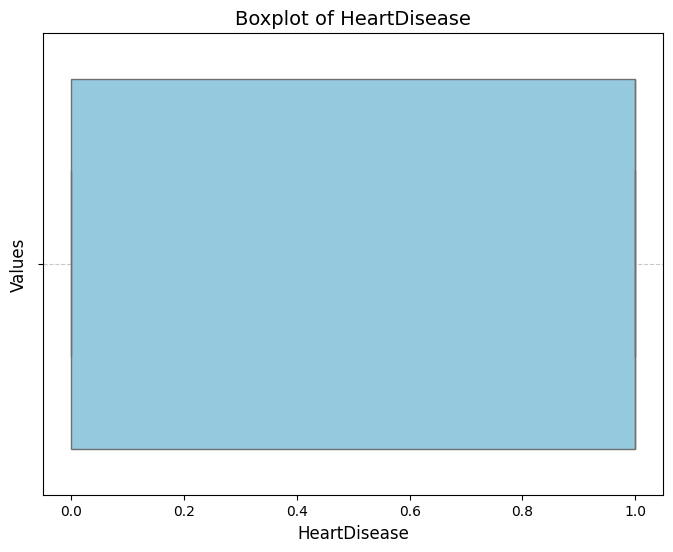

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

def plot_all_boxplots(df, color="skyblue"):
    """
    Genera boxplots para todas las columnas numéricas de un DataFrame.

    Parámetros:
    -----------
    df : pd.DataFrame
        El DataFrame que contiene las características a visualizar.
    color : str, default="skyblue"
        El color de los boxplots.

    Retorna:
    --------
    None
    """
    # Filtrar solo las columnas numéricas
    numeric_columns = df.select_dtypes(include=['number']).columns

    for feature in numeric_columns:
        plt.figure(figsize=(8, 6))
        sns.boxplot(data=df, x=feature, color=color)
        plt.title(f"Boxplot of {feature}", fontsize=14)
        plt.xlabel(feature, fontsize=12)
        plt.ylabel("Values", fontsize=12)
        plt.grid(axis="y", linestyle="--", alpha=0.7)
        plt.show()
plot_all_boxplots(data)

We apply capping to erase the outliers 

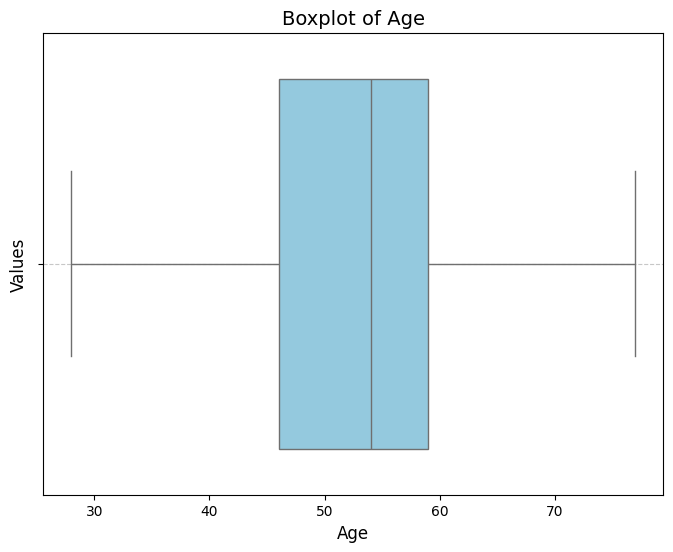

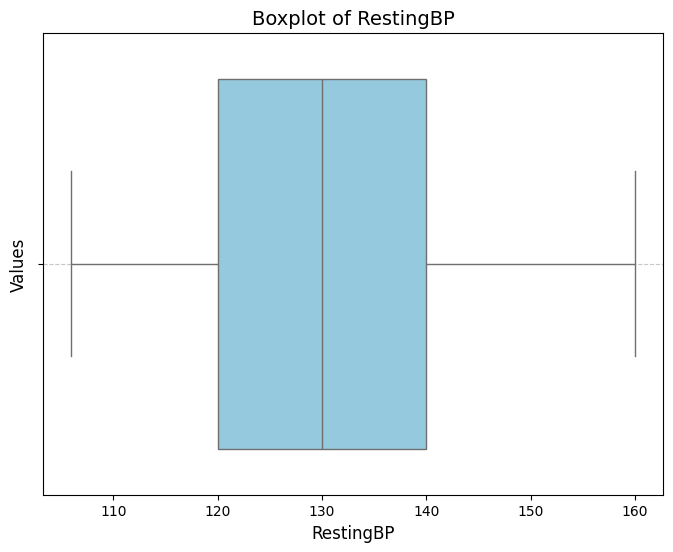

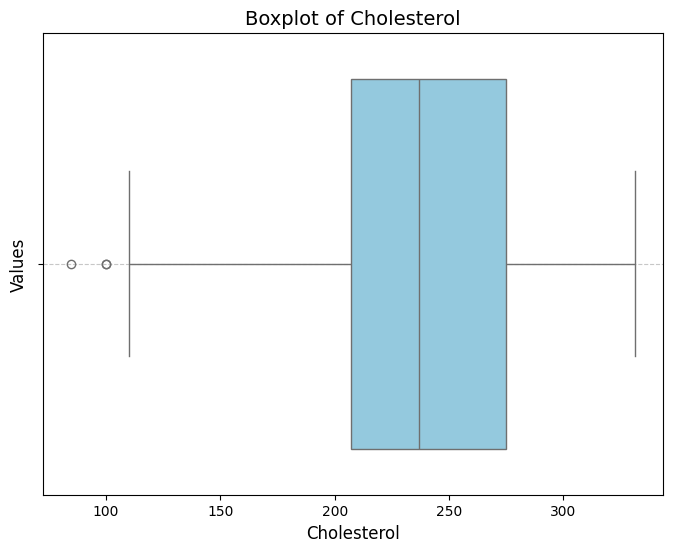

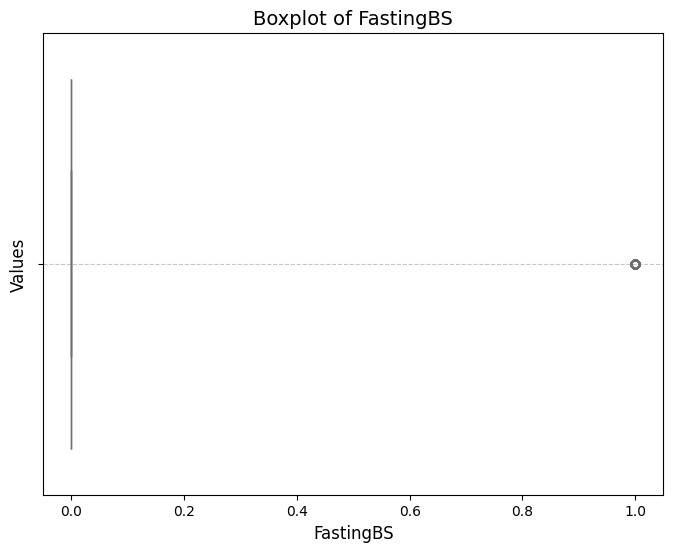

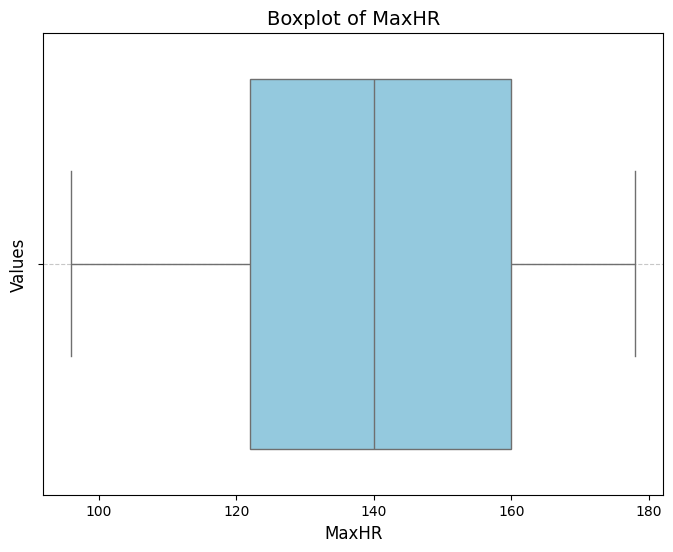

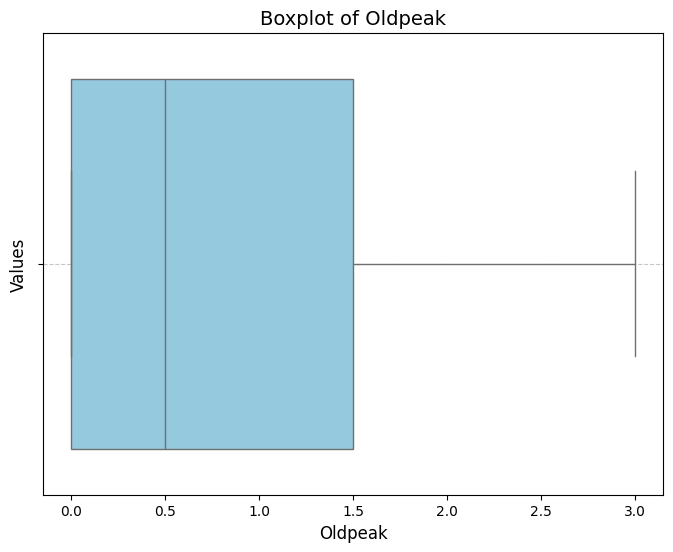

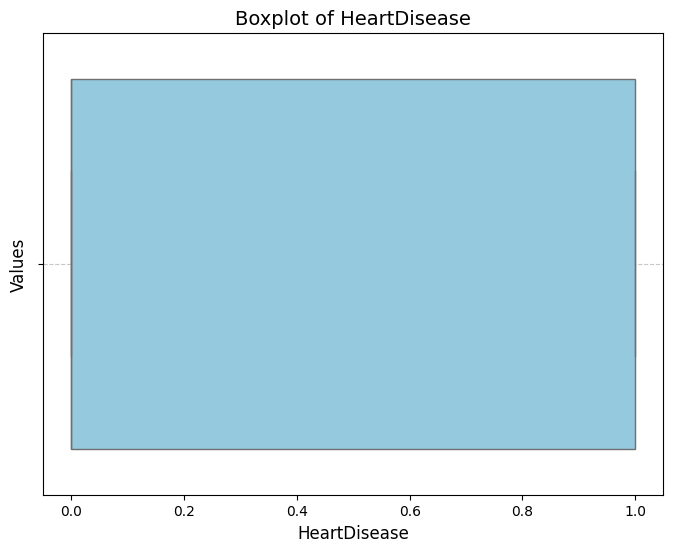

In [ ]:
import pandas as pd
import numpy as np

def cap_outliers(data, column_name, lower_percentile=0.05, upper_percentile=0.95):
    """
    Caps values in a column that are below the specified lower percentile and above the upper percentile.
    
    Args:
        data (pd.DataFrame): The DataFrame containing the data.
        column_name (str): The name of the column to apply capping.
        lower_percentile (float): The lower percentile threshold (default is 0.05, i.e., 5%).
        upper_percentile (float): The upper percentile threshold (default is 0.95, i.e., 95%).
    
    Returns:
        pd.DataFrame: The DataFrame with outliers capped.
    """
    # Calculate the lower and upper limits based on the specified percentiles
    lower_limit = data[column_name].quantile(lower_percentile)
    upper_limit = data[column_name].quantile(upper_percentile)
    
    # Cap values below the lower limit and above the upper limit
    data[column_name] = np.where(data[column_name] < lower_limit, lower_limit, data[column_name])
    data[column_name] = np.where(data[column_name] > upper_limit, upper_limit, data[column_name])
    
    return data

data = cap_outliers(data, 'Cholesterol')
data = cap_outliers(data, 'RestingBP')
data = cap_outliers(data, 'MaxHR')
data = cap_outliers(data, 'Oldpeak')

data = data[data["Cholesterol"] != 0]


plot_all_boxplots(data)

## FEATURE ENGINEERING
1) Label encoded columns  

In [ ]:
from sklearn.preprocessing import LabelEncoder
import pandas as pd

def label_encode_column(df, column_name):
    """
    Performs Label Encoding on a specified column using Scikit-learn's LabelEncoder.

    Args:
        df (pd.DataFrame): The DataFrame containing the data.
        column_name (str): The name of the column to encode.

    Returns:
        pd.DataFrame: A new DataFrame with the label-encoded column.
    """
    # Initialize the label encoder
    encoder = LabelEncoder()
    
    # Fit and transform the specified column
    df[column_name] = encoder.fit_transform(df[column_name])
    
    return df

label_encode_column(data, 'ChestPainType')
label_encode_column(data, 'Sex')
label_encode_column(data, 'RestingECG')
label_encode_column(data, 'ExerciseAngina')
label_encode_column(data, 'ST_Slope')

display(data.head())


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,1,1,140.0,289.0,0,1,172.0,0,0.0,2,0
1,49,0,2,160.0,180.0,0,1,156.0,0,1.0,1,1
2,37,1,1,130.0,283.0,0,2,98.0,0,0.0,2,0
3,48,0,0,138.0,214.0,0,1,108.0,1,1.5,1,1
4,54,1,2,150.0,195.0,0,1,122.0,0,0.0,2,0


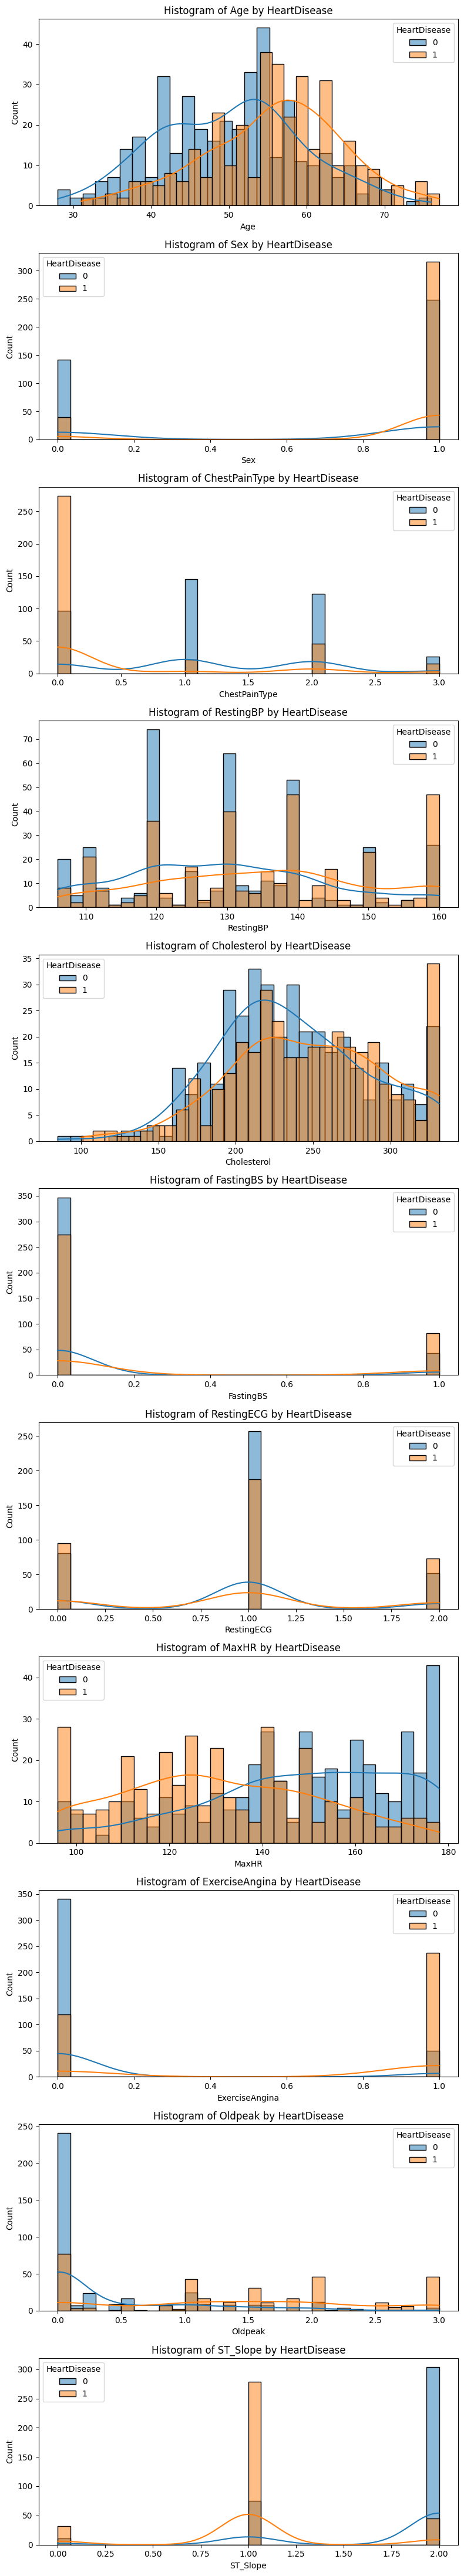

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

def plot_feature_histograms(df, target_feature, bins=30):
    """
    Genera histogramas de todas las características numéricas en función de una variable objetivo.

    Parámetros:
    - df: DataFrame de pandas
    - target_feature: Nombre de la columna objetivo (debe ser categórica o discreta)
    - bins: Número de bins para los histogramas
    """
    numeric_features = df.select_dtypes(include=['number']).columns
    numeric_features = [col for col in numeric_features if col != target_feature]
    
    unique_classes = df[target_feature].unique()
    num_features = len(numeric_features)
    
    fig, axes = plt.subplots(nrows=num_features, ncols=1, figsize=(8, 4 * num_features))
    
    if num_features == 1:
        axes = [axes]  # Asegura que axes sea iterable cuando hay solo una feature
    
    for ax, feature in zip(axes, numeric_features):
        for category in unique_classes:
            sns.histplot(df[df[target_feature] == category][feature], bins=bins, label=str(category), alpha=0.5, ax=ax, kde=True)
        
        ax.set_title(f'Histogram of {feature} by {target_feature}')
        ax.legend(title=target_feature)
    
    plt.tight_layout()
    plt.show()

plot_feature_histograms(data, 'HeartDisease')

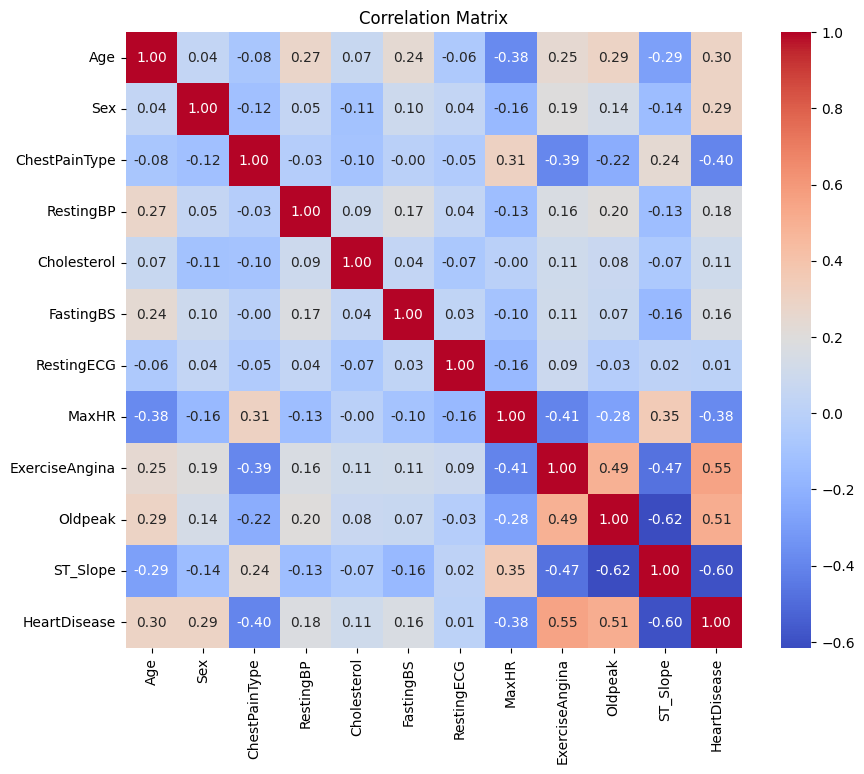

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

#MATRIZ DE CORRELACIÓN

def plot_correlation_matrix(data):
    """
    Plot a correlation matrix for all features in the dataset.

    Parameters:
    data (DataFrame): The input DataFrame containing all features.

    Returns:
    None
    """
    plt.figure(figsize=(10, 8))
    correlation_matrix = data.corr()
    sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', square=True, cbar=True)
    plt.title("Correlation Matrix")
    plt.show()
plot_correlation_matrix(data)

As ST_Slope is strongly correlated with Old peak we decide to get rid of the least relevant for our model 

In [ ]:
data = data.drop('Oldpeak', axis=1)
display(data.head())

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,ST_Slope,HeartDisease
0,40,1,1,140.0,289.0,0,1,172.0,0,2,0
1,49,0,2,160.0,180.0,0,1,156.0,0,1,1
2,37,1,1,130.0,283.0,0,2,98.0,0,2,0
3,48,0,0,138.0,214.0,0,1,108.0,1,1,1
4,54,1,2,150.0,195.0,0,1,122.0,0,2,0


We now standardize the numerical features only 

In [ ]:
from sklearn.preprocessing import StandardScaler
import pandas as pd

def standardize_features(data, features):
    """
    Estandariza características específicas del dataset.
    
    Parameters:
    - data: DataFrame con los datos.
    - features: Lista de características a estandarizar.
    
    Returns:
    - DataFrame con las características seleccionadas estandarizadas.
    """
    # Copia del dataset para no modificar el original
    data_standardized = data.copy()
    
    # Crear el escalador y aplicar a las características seleccionadas
    scaler = StandardScaler()
    data_standardized[features] = scaler.fit_transform(data[features])
    
    return data_standardized

features = ['Age', 'RestingBP', 'Cholesterol', 'MaxHR']    
data = standardize_features(data, features)

## TRAIN TEST
1) Split the data into train and test
2) Voting classifiers
3) Bagging 
4) Bagging with OOB
5) Adaboost
6) Stacking
7) XGBoost



In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report

X = data.drop('HeartDisease', axis=1)
y = data['HeartDisease']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
# Define base classifiers
clf1 = LogisticRegression()
clf2 = SVC(probability=True)
clf3 = DecisionTreeClassifier()

# Train and evaluate individual classifiers
clf1.fit(X_train, y_train)
clf2.fit(X_train, y_train)
clf3.fit(X_train, y_train)

accuracy_lr = accuracy_score(y_test, clf1.predict(X_test))
accuracy_svc = accuracy_score(y_test, clf2.predict(X_test))
accuracy_dt = accuracy_score(y_test, clf3.predict(X_test))

print("Logistic Regression Accuracy:", accuracy_lr)
print("SVC Accuracy:", accuracy_svc)
print("Decision Tree Accuracy:", accuracy_dt)

Logistic Regression Accuracy: 0.8666666666666667
SVC Accuracy: 0.8533333333333334
Decision Tree Accuracy: 0.8133333333333334


Hard Voting

In [ ]:
from sklearn.ensemble import VotingClassifier  
# Create a Voting Classifier (hard voting)
voting_clf_hard = VotingClassifier(estimators=[('lr', clf1), ('svc', clf2), ('dt', clf3)], voting='hard')
voting_clf_hard.fit(X_train, y_train)

# Evaluate the hard voting classifier
accuracy_hard = accuracy_score(y_test, voting_clf_hard.predict(X_test))
print("Hard Voting Classifier Accuracy:", accuracy_hard)


Hard Voting Classifier Accuracy: 0.88


In [ ]:
# Evaluate the hard voting classifier
accuracy_hard = accuracy_score(y_test, voting_clf_hard.predict(X_test))
print("Hard Voting Classifier Accuracy:", accuracy_hard)
print(classification_report(y_test, voting_clf_hard.predict(X_test)))

Hard Voting Classifier Accuracy: 0.88
              precision    recall  f1-score   support

           0       0.84      0.92      0.88        71
           1       0.92      0.85      0.88        79

    accuracy                           0.88       150
   macro avg       0.88      0.88      0.88       150
weighted avg       0.88      0.88      0.88       150



Soft Voting

In [ ]:
# Create a Voting Classifier (soft voting)
voting_clf_soft = VotingClassifier(estimators=[('lr', clf1), ('svc', clf2), ('dt', clf3)], voting='soft')
voting_clf_soft.fit(X_train, y_train)



VotingClassifier(estimators=[('lr', LogisticRegression()),
                             ('svc', SVC(probability=True)),
                             ('dt', DecisionTreeClassifier())],
                 voting='soft')

In [ ]:
# Evaluate the soft voting classifier
accuracy_soft = accuracy_score(y_test, voting_clf_soft.predict(X_test))
print("Soft Voting Classifier Accuracy:", accuracy_soft)
print(classification_report(y_test, voting_clf_soft.predict(X_test)))

Soft Voting Classifier Accuracy: 0.84
              precision    recall  f1-score   support

           0       0.78      0.92      0.84        71
           1       0.91      0.77      0.84        79

    accuracy                           0.84       150
   macro avg       0.85      0.84      0.84       150
weighted avg       0.85      0.84      0.84       150



bagging

In [ ]:
from sklearn.ensemble import BaggingClassifier
# Train Bagging Classifier
bagging_clf = BaggingClassifier(DecisionTreeClassifier(max_depth=6), n_estimators=50, bootstrap=True, n_jobs=-1)
bagging_clf.fit(X_train, y_train)

BaggingClassifier(estimator=DecisionTreeClassifier(max_depth=6),
                  n_estimators=50, n_jobs=-1)

In [ ]:
accuracy_bagging = accuracy_score(y_test, bagging_clf.predict(X_test))
print("Bagging Classifier Accuracy:", accuracy_bagging)
print(classification_report(y_test, bagging_clf.predict(X_test)))

Bagging Classifier Accuracy: 0.8933333333333333
              precision    recall  f1-score   support

           0       0.86      0.93      0.89        71
           1       0.93      0.86      0.89        79

    accuracy                           0.89       150
   macro avg       0.89      0.90      0.89       150
weighted avg       0.90      0.89      0.89       150



bagging with OOB

In [ ]:
# Bagging Classifier with OOB Score
bagging_clf = BaggingClassifier(
    DecisionTreeClassifier(max_depth=6),
    n_estimators=50,
    bootstrap=True,
    oob_score=True,  # Enables OOB scoring
    n_jobs=-1,
    random_state=42
)
bagging_clf.fit(X_train, y_train)

# Compute and print OOB Score
print("Bagging Classifier OOB Score:", bagging_clf.oob_score_)
print(classification_report(y_test, bagging_clf.predict(X_test)))

Bagging Classifier OOB Score: 0.8238255033557047
              precision    recall  f1-score   support

           0       0.83      0.92      0.87        71
           1       0.92      0.84      0.87        79

    accuracy                           0.87       150
   macro avg       0.88      0.88      0.87       150
weighted avg       0.88      0.87      0.87       150



Adaboost

In [ ]:
from sklearn.ensemble import AdaBoostClassifier
# AdaBoost Classifier
adaboost_clf = AdaBoostClassifier(DecisionTreeClassifier(max_depth=1), n_estimators=40, learning_rate=0.5, random_state=42)
adaboost_clf.fit(X_train, y_train)

AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1),
                   learning_rate=0.5, n_estimators=40, random_state=42)

In [ ]:
# Evaluate AdaBoost
accuracy_adaboost = accuracy_score(y_test, adaboost_clf.predict(X_test))
print("AdaBoost Classifier Accuracy:", accuracy_adaboost)
print(classification_report(y_test, adaboost_clf.predict(X_test)))

AdaBoost Classifier Accuracy: 0.88
              precision    recall  f1-score   support

           0       0.84      0.92      0.88        71
           1       0.92      0.85      0.88        79

    accuracy                           0.88       150
   macro avg       0.88      0.88      0.88       150
weighted avg       0.88      0.88      0.88       150



Stacking

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import StackingClassifier

# Define base models
base_models = [
    ('decision_tree', DecisionTreeClassifier(max_depth=6)),
    ('svm', SVC(probability=True)),
    ('logistic_regression', LogisticRegression())
]

# Define meta-model (blender)
meta_model = RandomForestClassifier(n_estimators=100, max_depth=6, random_state=42)

# Create Stacking Classifier
stacking_clf = StackingClassifier(estimators=base_models, final_estimator=meta_model, cv=5)
stacking_clf.fit(X_train, y_train)


StackingClassifier(cv=5,
                   estimators=[('decision_tree',
                                DecisionTreeClassifier(max_depth=6)),
                               ('svm', SVC(probability=True)),
                               ('logistic_regression', LogisticRegression())],
                   final_estimator=RandomForestClassifier(max_depth=6,
                                                          random_state=42))

In [ ]:
# Evaluate the Stacking Classifier
accuracy_stacking = accuracy_score(y_test, stacking_clf.predict(X_test))
print("Stacking Classifier Accuracy:", accuracy_stacking)
print(classification_report(y_test, stacking_clf.predict(X_test)))

Stacking Classifier Accuracy: 0.8533333333333334
              precision    recall  f1-score   support

           0       0.82      0.89      0.85        71
           1       0.89      0.82      0.86        79

    accuracy                           0.85       150
   macro avg       0.85      0.86      0.85       150
weighted avg       0.86      0.85      0.85       150



In [ ]:
# Train and evaluate base models
for name, model in base_models:
    model.fit(X_train, y_train)
    accuracy = accuracy_score(y_test, model.predict(X_test))
    print(f"{name} Accuracy: {accuracy}")

decision_tree Accuracy: 0.8133333333333334
svm Accuracy: 0.8533333333333334
logistic_regression Accuracy: 0.8666666666666667


XGBoost

In [ ]:
import xgboost as xgb

XGB_clf=xgb.XGBClassifier(max_depth=6, n_estimators=100, learning_rate=0.3)
XGB_clf.fit(X_train, y_train)



XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              gamma=None, grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.3, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=6, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=100, n_jobs=None,
              num_parallel_tree=None, random_state=None, ...)

In [ ]:
# Evaluate the Stacking Classifier
accuracy_stacking = accuracy_score(y_test, XGB_clf.predict(X_test))
print("XGBoost classifier Acccuracy:", accuracy_stacking)

XGBoost classifier Acccuracy: 0.9


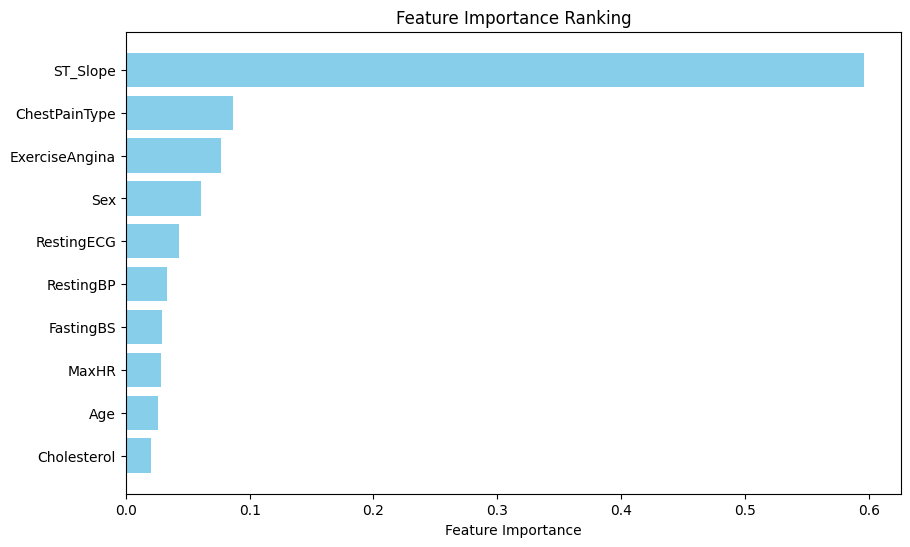

In [ ]:
#FEATURE IMPORTANCES 
import numpy as np

    

def plot_feature_importance(model, feature_names):
    """
    Plot the feature importance of a trained model.

    Parameters:
    model: The trained model with feature_importances_ attribute (e.g., RandomForest).
    feature_names (list): List of feature names used in the model.

    Returns:
    None
    """
    # Get feature importances and sort them
    importance_values = model.feature_importances_
    sorted_indices = np.argsort(importance_values)[::-1]
    sorted_importances = importance_values[sorted_indices]
    sorted_features = np.array(feature_names)[sorted_indices]

    # Plotting
    plt.figure(figsize=(10, 6))
    plt.barh(sorted_features, sorted_importances, color='skyblue')
    plt.xlabel("Feature Importance")
    plt.title("Feature Importance Ranking")
    plt.gca().invert_yaxis()
    plt.show()

features = X.columns

plot_feature_importance(XGB_clf, features)


## Hyperparameters 
We are gonna compare some models tuning its hyperparameters and at the end with the grid search 
1) Bagging with OOB
2) Adaboost

Bagging with OOb

In [ ]:
from sklearn.ensemble import BaggingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, accuracy_score

def train_and_evaluate(n_estimators, estimator__max_depth, max_features, max_samples):
    base_estimator = DecisionTreeClassifier(max_depth=estimator__max_depth, random_state=42)
    
    bagging_clf = BaggingClassifier(
        estimator=base_estimator,
        n_estimators=n_estimators,
        max_features=max_features,
        max_samples=max_samples,
        bootstrap=True,
        oob_score=True,
        n_jobs=-1,
        random_state=42
    )
    
    bagging_clf.fit(X_train, y_train)
    
    print(f"\nParámetros: n_estimators={n_estimators}, estimator__max_depth={estimator__max_depth}, "
          f"max_features={max_features}, max_samples={max_samples}")
    print(f"OOB Score: {bagging_clf.oob_score_:.4f}")
    
    y_pred = bagging_clf.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)
    print(f"Test Accuracy: {accuracy:.4f}")
    print(classification_report(y_test, y_pred))

train_and_evaluate(n_estimators=50, estimator__max_depth=6, max_features=0.5, max_samples=0.5)
train_and_evaluate(n_estimators=100, estimator__max_depth=9, max_features=1.0, max_samples=0.7)



Parámetros: n_estimators=50, estimator__max_depth=6, max_features=0.5, max_samples=0.5
OOB Score: 0.8406
Test Accuracy: 0.8733
              precision    recall  f1-score   support

           0       0.84      0.90      0.87        71
           1       0.91      0.85      0.88        79

    accuracy                           0.87       150
   macro avg       0.87      0.87      0.87       150
weighted avg       0.88      0.87      0.87       150


Parámetros: n_estimators=100, estimator__max_depth=9, max_features=1.0, max_samples=0.7
OOB Score: 0.8322
Test Accuracy: 0.8933
              precision    recall  f1-score   support

           0       0.85      0.94      0.89        71
           1       0.94      0.85      0.89        79

    accuracy                           0.89       150
   macro avg       0.90      0.90      0.89       150
weighted avg       0.90      0.89      0.89       150



In [ ]:
from sklearn.ensemble import BaggingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report, accuracy_score

base_clf = DecisionTreeClassifier()

param_grid = {
    'estimator__max_depth': [3, 6, 9],
    'n_estimators': [10, 50, 100],
    'max_features': [0.5, 1.0],
    'max_samples': [0.5, 0.7, 1.0]
}

bagging_clf = BaggingClassifier(
    estimator=base_clf,
    bootstrap=True,
    oob_score=True,
    n_jobs=-1,
    random_state=42
)

grid_search = GridSearchCV(bagging_clf, param_grid, cv=5, scoring='accuracy')
grid_search.fit(X_train, y_train)

print("Best parameters:", grid_search.best_params_)

best_bagging_clf = grid_search.best_estimator_
best_bagging_clf.fit(X_train, y_train)

y_pred = best_bagging_clf.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
print("\nBagging Classifier OOB Score:", best_bagging_clf.oob_score_)
print("Test Accuracy:", accuracy)
print(classification_report(y_test, y_pred))


Best parameters: {'estimator__max_depth': 3, 'max_features': 1.0, 'max_samples': 1.0, 'n_estimators': 50}

Bagging Classifier OOB Score: 0.8338926174496645
Test Accuracy: 0.9
              precision    recall  f1-score   support

           0       0.89      0.90      0.90        71
           1       0.91      0.90      0.90        79

    accuracy                           0.90       150
   macro avg       0.90      0.90      0.90       150
weighted avg       0.90      0.90      0.90       150



The best accuracy comes with this hypervalues : 'estimator__max_depth': 3, 'max_features': 1.0, 'max_samples': 1.0, 'n_estimators': 50

Adaboost

In [ ]:
from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, accuracy_score

def train_and_evaluate_adaboost(n_estimators, learning_rate, base_estimator__max_depth):
    base_estimator = DecisionTreeClassifier(max_depth=base_estimator__max_depth)
    
    adaboost_clf = AdaBoostClassifier(
        estimator=base_estimator,
        n_estimators=n_estimators,
        learning_rate=learning_rate,
        random_state=42
    )
    
    adaboost_clf.fit(X_train, y_train)
    
    print(f"\nParámetros: n_estimators={n_estimators}, learning_rate={learning_rate}, "
          f"base_estimator__max_depth={base_estimator__max_depth}")
    
    y_pred = adaboost_clf.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)
    print(f"Test Accuracy: {accuracy:.4f}")
    print(classification_report(y_test, y_pred))

# 1 : Initial configuration
train_and_evaluate_adaboost(n_estimators=50, learning_rate=1.0, base_estimator__max_depth=1)

# 2: Increase n_estimators
train_and_evaluate_adaboost(n_estimators=100, learning_rate=1.0, base_estimator__max_depth=1)

# 3: Adjust learning_rate
train_and_evaluate_adaboost(n_estimators=100, learning_rate=0.5, base_estimator__max_depth=1)

# 4: Increase max_depth from base estimator
train_and_evaluate_adaboost(n_estimators=100, learning_rate=0.5, base_estimator__max_depth=3)



Parámetros: n_estimators=50, learning_rate=1.0, base_estimator__max_depth=1
Test Accuracy: 0.8467
              precision    recall  f1-score   support

           0       0.82      0.87      0.84        71
           1       0.88      0.82      0.85        79

    accuracy                           0.85       150
   macro avg       0.85      0.85      0.85       150
weighted avg       0.85      0.85      0.85       150




Parámetros: n_estimators=100, learning_rate=1.0, base_estimator__max_depth=1
Test Accuracy: 0.8533
              precision    recall  f1-score   support

           0       0.82      0.89      0.85        71
           1       0.89      0.82      0.86        79

    accuracy                           0.85       150
   macro avg       0.85      0.86      0.85       150
weighted avg       0.86      0.85      0.85       150


Parámetros: n_estimators=100, learning_rate=0.5, base_estimator__max_depth=1
Test Accuracy: 0.8667
              precision    recall  f1-score   support

           0       0.83      0.90      0.86        71
           1       0.90      0.84      0.87        79

    accuracy                           0.87       150
   macro avg       0.87      0.87      0.87       150
weighted avg       0.87      0.87      0.87       150


Parámetros: n_estimators=100, learning_rate=0.5, base_estimator__max_depth=3
Test Accuracy: 0.8267
              precision    recall  f1-score   

In [ ]:
from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, classification_report

# Define AdaBoost classifier with DecisionTreeClassifier as base estimator
adaboost_clf = AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1), random_state=42)

# Define parameter grid for GridSearchCV
param_grid = {
    'n_estimators': [50, 100, 150],  # Number of estimators (trees)
    'learning_rate': [0.1, 0.5, 1.0],  # Learning rate for AdaBoost
    'estimator__max_depth': [1, 3, 5]  # Max depth of base estimator
}

# Apply GridSearchCV
grid_search = GridSearchCV(adaboost_clf, param_grid, cv=5, scoring='accuracy', n_jobs=-1)
grid_search.fit(X_train, y_train)

# Best model from GridSearchCV
best_adaboost_clf = grid_search.best_estimator_

# Evaluate the best model
accuracy_adaboost = accuracy_score(y_test, best_adaboost_clf.predict(X_test))
print("\nBest AdaBoost Classifier Accuracy:", accuracy_adaboost)
print(classification_report(y_test, best_adaboost_clf.predict(X_test)))

# Print the best parameters found by GridSearchCV
print("\nBest Parameters from GridSearchCV:", grid_search.best_params_)


Best AdaBoost Classifier Accuracy: 0.8866666666666667
              precision    recall  f1-score   support

           0       0.86      0.90      0.88        71
           1       0.91      0.87      0.89        79

    accuracy                           0.89       150
   macro avg       0.89      0.89      0.89       150
weighted avg       0.89      0.89      0.89       150


Best Parameters from GridSearchCV: {'estimator__max_depth': 1, 'learning_rate': 0.1, 'n_estimators': 50}


Best hyperparameters : 'estimator__max_depth': 1, 'learning_rate': 0.1, 'n_estimators': 50

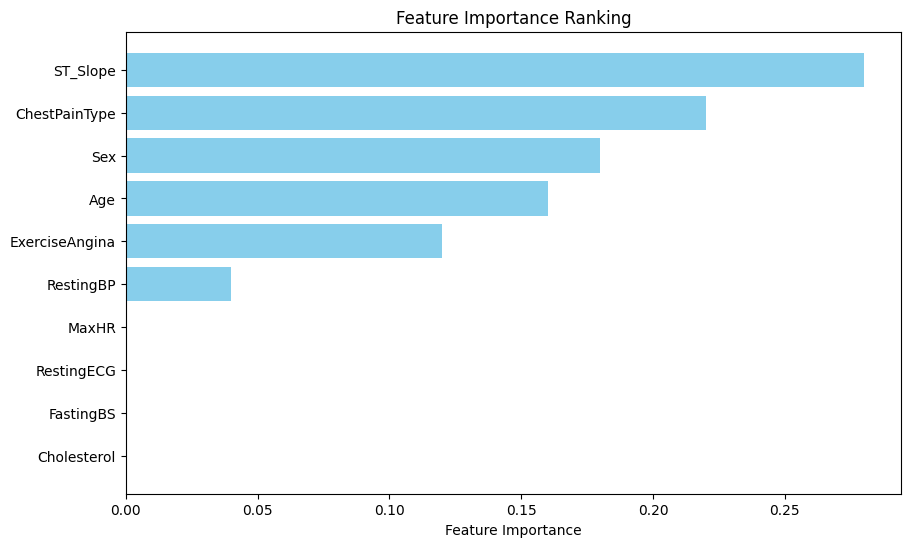

In [ ]:
#FEATURE IMPORTANCES 
import numpy as np

    

def plot_feature_importance(model, feature_names):
    """
    Plot the feature importance of a trained model.

    Parameters:
    model: The trained model with feature_importances_ attribute (e.g., RandomForest).
    feature_names (list): List of feature names used in the model.

    Returns:
    None
    """
    # Get feature importances and sort them
    importance_values = model.feature_importances_
    sorted_indices = np.argsort(importance_values)[::-1]
    sorted_importances = importance_values[sorted_indices]
    sorted_features = np.array(feature_names)[sorted_indices]

    # Plotting
    plt.figure(figsize=(10, 6))
    plt.barh(sorted_features, sorted_importances, color='skyblue')
    plt.xlabel("Feature Importance")
    plt.title("Feature Importance Ranking")
    plt.gca().invert_yaxis()
    plt.show()
features = X.columns
plot_feature_importance(best_adaboost_clf, features)



## RESUME
I have loaded the data set at the first instance.
Then a bit of data cleaning :
1) Missing values 
2) Identifying outliers with the boxplots

Then we have done Feature Engineering:
1) Seeing the correlatión of all the features (Correlation matrix)
2) Applying a labels encoder to the categorical features 
3) standardize the numerical features 

And here is a resume of the scores obtains in each type of model used :

1) Hard Voting score = 0.88 
2) Soft Voting score = 0.8533333334 
3) Bagging Classifier Accuracy: 0.8733333333333333
4) AdaBoost Classifier Accuracy: 0.88
5) Stacking Classifier Accuracy: 0.8666666666666667
6) XGBoost Accuracy : 0.9




Voting used with these three models :  Logistic Regression ,SVC Accuracy and Decision Tree.
Bagging with a decision Tree classifier.
Stacking with these three staking classifiers : Decision tree , SVC, LogisticRegression , and the final model was : Random Forrest

With the tuning of tho model with hyperparameters we obtain the next upgrade :
1) Bagging we improved from 0.8733 to 0.9
2) Adaboost we have improved from 0.88 to 0.88666667

For the importance of the features in each model , i have only used is those model that have attributes like adaboost or xgBoost.




